# Trying the dynamic problem with PS-GKS...

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
#!/usr/bin/env python
"""
Demo for Emoji dynamic tomography test problem
--------------------------------------------------------------------------
Created in 2023 for TRIPs-Py library
"""
__authors__ = "Mirjeta Pasha and Silvia Gazzola"
__affiliations__ = 'MIT and Tufts University, University of Bath'
__copyright__ = "Copyright 2023, TRIPs-Py library"
__license__ = "Apache"
__version__ = "1.0"
__email__ = "mpasha@mit.edu; mirjeta.pasha1@gmail.com; sg968@bath.ac.uk;"

In [3]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from scipy.linalg import fractional_matrix_power
from numpy import array, diag, dot, maximum, empty, repeat, ones, sum
from numpy.linalg import inv
import scipy as sp
import scipy.stats as sps
import scipy.io as spio
import astra
from venv import create
import pylops
from scipy import sparse
from scipy.ndimage import convolve
import scipy.special as spe
import requests
import h5py
from trips.utilities.io import *
from trips.utilities.operators import *
from trips.utilities.helpers import *
from trips.solvers.GKS import *
from trips.solvers.MMGKS import *


import sys
sys.path.append("../")



# # Go three directories up
# current_dir = os.path.dirname(os.getcwd())
# three_dirs_up = os.path.abspath(os.path.join(current_dir, '..', '..'))
# sys.path.append(three_dirs_up)


# from msolver import MM2019GKS, IASGKS, VanillaGKS, MMGKS, MM3GKS, MM2GKS, MMXGKS
# from fsolver import IASFGK, MM2019FGK, MMFGK, MM3FGK, MMXFGK # VanillaFK
# from pgkbsolver import MM2019GKB, IASGKB, MMGKB, MM3GKB, MMXGKB
# from f2019solver import MM2019FGK2019, IASFGK2019

# from pinv import CGWeightedNeumann2DPinvOperatorGP

/home/jlindbloom/miniconda3/envs/jlinops/lib/python3.11/site-packages/cupyx/jit/_interface.py:173: FutureWarning: cupyx.jit.rawkernel is experimental. The interface can change in the future.
  cupy._util.experimental('cupyx.jit.rawkernel')


# Try V-GKS, S-GKS, PS-GKS with spatiotemporal prior?

## V-GKS

In [4]:
import jlinops

from msolver import VanillaGKS
from msolver import MMGKS as MyMMGKS

from voxelgrad import build_spatiotemporal_neumann2d

In [5]:
(F, d, Aseq, B, nx, ny, nt) = generate_emoji(dataset = 30)

data already downloaded.


In [6]:
voxel_shape = (nx, ny, nt)
L = build_spatiotemporal_neumann2d(voxel_shape)

In [7]:
L.shape

(1622016, 540672)

In [8]:
time_step = 5
A1 = Aseq[time_step]
b1 = B[time_step]
L = jlinops.Neumann2D((nx,ny))
data_vec = d.reshape((-1,1))
# Use GKS to compute an approximate solution
#(x_mmgks_1, info_mmgks_1) = MMGKS(A1, b1.reshape((-1,1)), L, pnorm = 2, qnorm = 1, projection_dim = 1, n_iter = 100, regparam = 'gcv', x_true = None, epsilon = 0.001)

In [9]:
v_gks_solver = VanillaGKS(A1, L, b1, noise_var=0.4*0.1, img_shape=(nx,ny))

In [10]:
vdata = v_gks_solver.solve(n_iter=30, init_dim=5)

18531.02536983484
27706.924656713014
29928.431537449345
29956.524371843243


28805.245252890756
28046.059905083228
27506.815887194167
27233.774735632574
27103.659309302537
27071.987310441084
27080.735736274506
27126.408480218746
27198.679379304052
27276.292767691866
27385.67479972733
27484.810422488295
27568.15914568583
27647.098466865704
27701.432766474678
27752.35056586074
27802.819510583213
27842.575273364037
27871.37473218674
27889.637010938535
27900.483753483542
27902.870600863356
27902.81999465087
27899.930411451172
27894.428699844724
27891.216959244197


In [65]:
plt.imshow(vdata["x"].reshape((nx,ny)))
plt.show()

NameError: name 'vdata' is not defined

### Do spatiotemporal but still just L2?

In [9]:
from jlinops import _CustomLinearOperator

class RectBlockDiagonalOperator(_CustomLinearOperator):
    """Given (rectangular) operators A_1, \ldots, A_p of shapes m_i \times n, represents the block diagonal operator diag(A_1, \ldots, A_p).
    """
    def __init__(self, As, device="cpu", type=1):

        # Setup
        self.As = As # list of operators
        self.p = len(self.As) # number of operators
        self.n = As[0].shape[1]
        self.ms = [] # list of shapes
        self.idxs = []
        self.mvec_idxs = []
        self.rmvec_idxs = []
        mvec_tmp = 0
        rmvec_tmp = 0
        for j, op in enumerate(self.As):
            mj = op.shape[0]
            assert op.shape[1] == self.n, "Not all A_i have same number of columns!"
            self.ms.append(mj)

            if j == 0:
                self.mvec_idxs.append( np.arange(self.n) )
                self.rmvec_idxs.append( np.arange(mj) )
                #self.idxs.append( np.arange(nj) )     
            else:
                self.mvec_idxs.append( np.arange(mvec_tmp, mvec_tmp+self.n) )
                self.rmvec_idxs.append( np.arange(rmvec_tmp, rmvec_tmp+mj) )
                #self.idxs.append( np.arange(tmp, tmp+nj) )
                
            mvec_tmp += self.n
            rmvec_tmp += mj


        # Set shape
        n_tot = len(As)*self.n
        shape = (sum(self.ms), n_tot)
        print(shape)

        # Define matvecs
        def _matvec(x):
            x = x.reshape(-1)
            pieces = []
            for j, op in enumerate(self.As):
                pieces.append( op.matvec(x[self.mvec_idxs[j]]) )
            return np.hstack(pieces)
        
        def _rmatvec(x):
            x = x.reshape(-1)
            pieces = []
            for j, op in enumerate(self.As):
                pieces.append( op.rmatvec(x[self.rmvec_idxs[j]]) )
            return np.hstack(pieces)

            
        super().__init__(shape, _matvec, _rmatvec, device=device)
                
                
        
    def to_gpu(self):

        As_gpu = []
        for op in self.As:
            gpu_op = op.to_gpu()
            As_gpu.append(gpu_op)

        return RectBlockDiagonalOperator(As_gpu, device="gpu")
    
    def to_cpu(self):

        As_cpu = []
        for op in self.As:
            cpu_op = op.to_cpu()
            As_cpu.append(cpu_op)

        return RectBlockDiagonalOperator(As_cpu, device="cpu")

In [ ]:
from jlinops import _CustomLinearOperator

class VoxelDynamicTomoOperator(_CustomLinearOperator):
    """
    """
    def __init__(self, As, voxel_shape, device="cpu"):

        # Setup
        self.As = As # list of operators
        self.p = len(self.As) # number of operators
        self.voxel_shape = voxel_shape
        self.n = self.As[0].shape[1]
        self.Nx, self.Ny, self.Nt = self.voxel_shape
        self.ms = []
        self.rmvec_idxs = []
        rmvec_tmp = 0
        for j, op in enumerate(self.As):
            mj = op.shape[0]
            assert op.shape[1] == self.n, "Not all A_i have same number of columns!"
            self.ms.append(mj)

            if j == 0:
                self.rmvec_idxs.append( np.arange(mj) )
                #self.idxs.append( np.arange(nj) )     
            else:
                self.rmvec_idxs.append( np.arange(rmvec_tmp, rmvec_tmp+mj) )
                #self.idxs.append( np.arange(tmp, tmp+nj) )

            rmvec_tmp += mj

        shape = ( sum(self.ms) , self.Nx*self.Ny*self.Nt)


        def _matvec(x):
            x = x.reshape(self.voxel_shape)
            result = []
            for j in range(self.p):
                result.append( self.As[j] @ x[:,:,j].flatten() ) # Apply Aj to jth temporal slice
            result = np.vstack(result)
            return result
        

        def _rmatvec(x):

            result = np.zeros(self.voxel_shape)
            for j, op in enumerate(self.As):
                result[:,:,j] = op.rmatvec(x[self.rmvec_idxs[j]]).reshape((self.Nx, self.Ny))
                
            return result.flatten()


        super().__init__(shape, _matvec, _rmatvec, device=device)

    
        
    # def to_gpu(self):

    #     As_gpu = []
    #     for op in self.As:
    #         gpu_op = op.to_gpu()
    #         As_gpu.append(gpu_op)

    #     return RectBlockDiagonalOperator(As_gpu, device="gpu")
    
    # def to_cpu(self):

    #     As_cpu = []
    #     for op in self.As:
    #         cpu_op = op.to_cpu()
    #         As_cpu.append(cpu_op)

    #     return RectBlockDiagonalOperator(As_cpu, device="cpu")

In [11]:
how_many = 30
voxel_shape = (nx, ny, how_many)
A9 = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in range(how_many) ], voxel_shape)
b9 = np.hstack(B[:how_many])
L = build_spatiotemporal_neumann2d(voxel_shape)
NOISE_VAR = 0.1

In [12]:
# 0.4*0.1
v_gks_solver = VanillaGKS(A9, L, b9, noise_var=NOISE_VAR, img_shape=(nx,ny))

In [13]:
vdata = v_gks_solver.solve(n_iter=30, init_dim=5)

5184.948310028237
11432.813937353103


KeyboardInterrupt: 

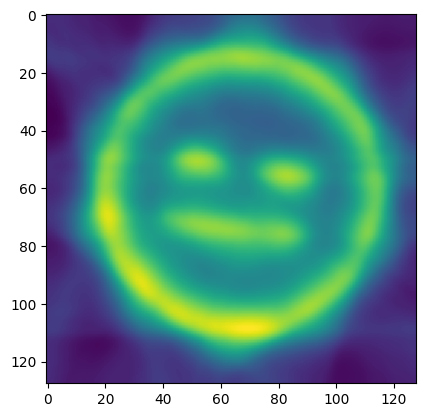

In [112]:
plt.imshow(vdata["x"].reshape((nx,ny,how_many))[:,:,0])
plt.show()

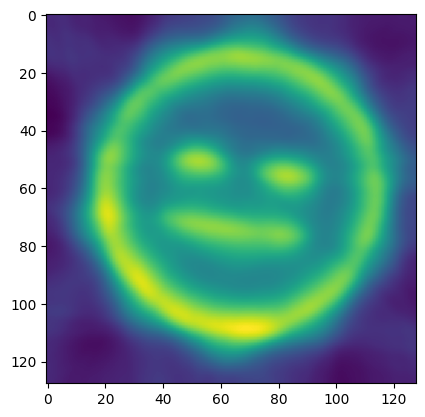

In [113]:
plt.imshow(vdata["x"].reshape((nx,ny,how_many))[:,:,1])
plt.show()

## S-GKS (MM weights), just one

In [30]:
A9 = Aseq[0]
b9 = B[0]
grid_shape = (nx, ny)
L = jlinops.Neumann2D((nx, ny))
NOISE_VAR = 0.1

In [31]:
mm_sgks_solver = MyMMGKS(A9, L, b9, noise_var=NOISE_VAR)

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}

In [32]:
mm_sgks_data = mm_sgks_solver.solve(n_iter=100, weight_params=mm_weight_params)

215118.92905715416
51.566027015856235
58.30136266449836
63.14270899189259
66.36881669689105
69.19254434709903
71.79036530637656
73.72487152815248
74.98569832054494
75.82369829363908
76.1890129804263
76.32896184131502
76.3861946819079
76.40412699692064
76.41181118638322
76.43205083043156
76.49582595537191
76.62341981542376
76.79564023146347
76.9553640800564
77.06630829369028
77.12603238985976
77.1586465221063
77.17219454142128
77.17496564229134
77.17525083147589
77.1792748364064
77.19198874658387
77.21354996451845
77.24436991208587
77.29217775425361
77.374420048266
77.48141267705509
77.58860108488469
77.6742794749651
77.724193630261
77.73780662430916
77.73862997190074
77.73755186320852
77.73927692232057
77.74000956039342
77.73599050555673
77.72940945157373
77.7259973201225
77.72623743520423
77.72828232740858
77.75157225472915
77.79935054822347
77.85775483285735
77.89785865640164
77.90620401773019
77.90987969528025
77.92751786172953
77.94664601790005
77.95658963415183
77.95416523240108
7

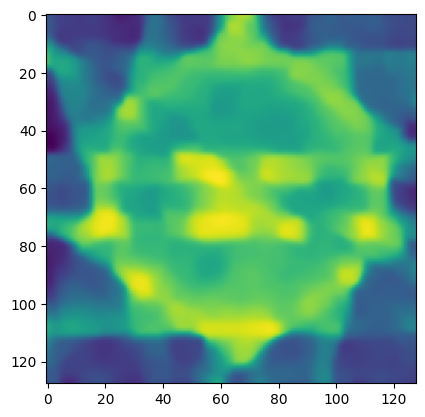

In [34]:
plt.imshow(mm_sgks_data["x"].reshape((nx,ny)))
plt.show()

## S-GKS (MM weights), multiple

In [46]:
how_many = 10
voxel_shape = (nx, ny, how_many)
A9 = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in range(how_many) ], voxel_shape)
b9 = np.hstack(B[:how_many])
L = build_spatiotemporal_neumann2d(voxel_shape)
NOISE_VAR = 0.1

In [47]:
mm_sgks_solver = MyMMGKS(A9, L, b9, noise_var=NOISE_VAR)

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}

In [48]:
mm_sgks_data = mm_sgks_solver.solve(n_iter=50, weight_params=mm_weight_params)

86515.64940134302
20.79497817044315
24.581721734812884
26.47837979312765
28.07439973482811
29.274387673509594
30.22555147279914
31.007045110294676
31.735812272370822
32.59364769932898
33.668651950526986
34.8701420706286
36.130064472785136
37.40306468307858
38.547772284876736
39.42842855633861
39.99545100773105
40.32096773002526
40.50110217708551
40.57645266260226
40.59570861450182
40.59424018130109
40.5899828306538
40.58938807969266
40.6046928913812
40.66152549975537
40.78204878087589
40.9237450673773
41.02393193352256
41.06702906041461
41.081874334844535
41.0843433799585
41.09187518980341
41.1237073461129
41.17356853428364
41.2065060132814
41.2109082035377
41.20819335679581
41.21089833284303
41.21958991379669
41.2302475314823
41.23161820935034
41.23144306686757
41.23161536133462
41.22649004544972
41.22562313733955
41.23598437390626
41.25900619637595
41.29556449025124
41.34635283280466


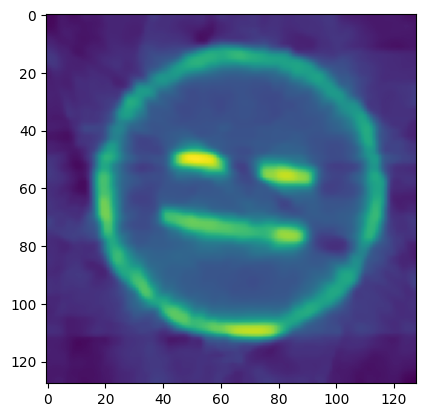

In [49]:
plt.imshow(mm_sgks_data["x"].reshape((nx,ny,how_many))[:,:,0])
plt.show()

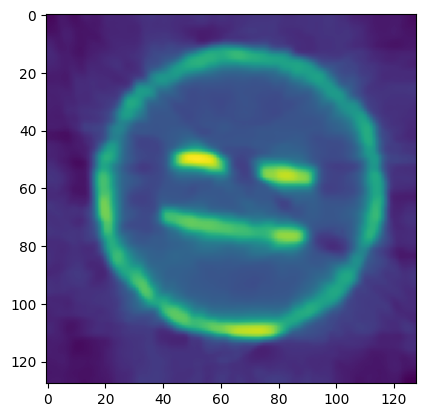

In [50]:
plt.imshow(mm_sgks_data["x"].reshape((nx,ny,how_many))[:,:,1])
plt.show()

## PS-GKS?

In [63]:
from voxelgrad import CGWeightedVoxelGradPinvGPUOperator

from msolver import IASGKS

In [64]:
how_many = 5
voxel_shape = (nx, ny, how_many)
A9 = VoxelDynamicTomoOperator([ jlinops.MatrixLinearOperator(Aseq[i]) for i in range(how_many) ], voxel_shape)
b9 = np.hstack(B[:how_many])
L = build_spatiotemporal_neumann2d(voxel_shape)
NOISE_VAR = 0.1

In [56]:
K = np.ones(A9.shape[1])
K = K/np.linalg.norm(K)
K = jlinops.MatrixLinearOperator(K)

def Lpinv_factory(w, *args, **kwargs):
    return CGWeightedVoxelGradPinvGPUOperator(voxel_shape, weights=w, tol=1e-4, *args, **kwargs)


mm_sgks_solver = MyMMGKS(A9, L, b9, noise_var=NOISE_VAR, K=K, Lpinv_factory=Lpinv_factory)

mm_weight_params = {
    "q": 1.0,
    "epsilon": 1e-4,
}

In [57]:
mm_psgks_data = mm_sgks_solver.solve_with_priorconditioning(n_iter=35, weight_params=mm_weight_params)

/home/jlindbloom/Github/IRLS_prec_GSBL/voxelgrad_testing/../msolver.py:923: UserWarning: Inequality is NOT satisfied, no solution to the DP problem...
  warnings.warn("Inequality is NOT satisfied, no solution to the DP problem...", UserWarning)


1e-06
22.43389998333559
36.83175120182631
40.94396229256113
43.840865644247735
45.78383258953157
46.49356688486288
47.16050119753588
48.048166796057764
48.69671344110934
49.16082498961558
49.44679994988085
49.709012400903205
50.00682554635669
50.26380860001082
50.40910543770787
50.57412487017135
50.72720309983463
50.84849484391713
50.96195486191417
51.06107305411824
51.1501331807021
51.229678006115826
51.30141936119084
51.36616825611899
51.42366651786087
51.47749218016812
51.5265226782775
51.56907268803369
51.61045800316049
51.648453629072385
51.68132419091265
51.71434100547317
51.74318845548684
51.7706471654657


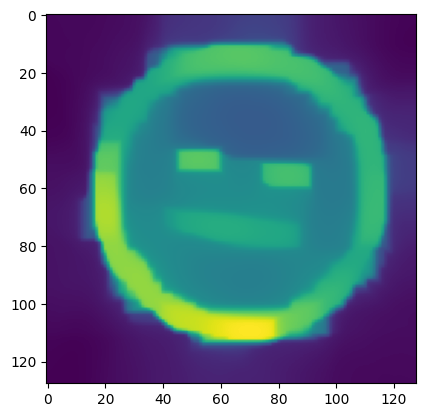

In [58]:
plt.imshow(mm_psgks_data["x"].reshape((nx,ny,how_many))[:,:,0])
plt.show()

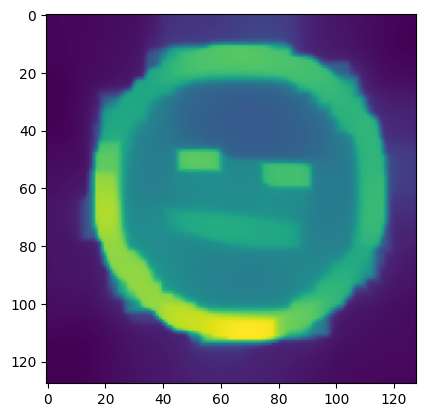

In [59]:
plt.imshow(mm_psgks_data["x"].reshape((nx,ny,how_many))[:,:,1])
plt.show()

In [61]:
plt.plot(mm_sgks_data["rre_hist"])

KeyError: 'rre_hist'

In [62]:
mm_sgks_data.keys()

dict_keys(['x', 'w', 'lambdah', 'tot_matvec_A', 'tot_matvec_L', 'tot_matvec_WLpinv', 'residual_history', 'lambda_history', 'V', 'cond_ests', 'dp_ineq_lhs', 'dp_ineq_rhs', 'dp_ineq_chs', 'n_completed_iterations', 'solution_history', 'hoyer_indices', 'gini_indices'])